# Test anisotropic polarization rotation reconstruction
This notebook exercises `CMBobs` → Plancklens filtering → the `a_p` quadratic estimator → response normalization and semi-analytical disconnected noise.

We compare an ensemble with injected anisotropic rotation against a matched **zero-rotation control**. The signal and control share the same CMB and noise seeds. Miscalibration is zero to isolate the spatial field. The default small ensemble is a diagnostic, not a precision calibration.

All rotation spectra are in radians squared. Only $L\geq2$ are plotted: the injected field has zero monopole and dipole. No mean-field, N1, or higher-order correction is subtracted.

In [7]:
%matplotlib inline
import hashlib
import json
from pathlib import Path
import time

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
from sim import CMBobs
from recon import AlphaRecon

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})

# Editable single-frequency test configuration.
nside = 512
nlevp = 2.0        # uK-arcmin
fwhm = 8.0       # arcmin
Acb = 1e-5        # rad^2: L(L+1) C_L^aa / (2 pi)
lmin_ivf = 20
lmax_ivf = 1500
lmax_qlm = 1024
nsims = 4         # increase for a tighter ensemble test
first_idx = 0
bin_width = 8
assert nsims >= 2, 'At least two realizations are needed for sample error bars'

config = dict(nside=nside, nlevp=nlevp, fwhm=fwhm, Acb=Acb,
              lmin_ivf=lmin_ivf, lmax_ivf=lmax_ivf, lmax_qlm=lmax_qlm)
# Separate cache directories when physical/filter parameters change.
tag = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
cache_root = Path('data') / 'reconstruction_test' / tag
obs = CMBobs(nside, nlevp, fwhm, alpha=0.2, Acb=Acb)
null_obs = CMBobs(nside, nlevp, fwhm, alpha=None, Acb=0)
kwargs = dict(lmin_ivf=lmin_ivf, lmax_ivf=lmax_ivf, lmax_qlm=lmax_qlm)
rec = AlphaRecon(obs, cache_root / 'signal', **kwargs)
null_rec = AlphaRecon(null_obs, cache_root / 'null', **kwargs)
print(json.dumps(config, indent=2))
print('Cache:', cache_root)

/Users/antoidicherianlonappan/Software/plancklens/plancklens/utils.py:124: RuntimeWarning: overflow encountered in cast
  return hashlib.sha1(np.copy(cl.astype(dtype), order='C')).hexdigest()


Caching sky fractions...
Caching sky fractions...
{
  "nside": 512,
  "nlevp": 2.0,
  "fwhm": 8.0,
  "Acb": 1e-05,
  "lmin_ivf": 20,
  "lmax_ivf": 1500,
  "lmax_qlm": 1024
}
Cache: data/reconstruction_test/57935800bcd4


## Normalization and spectra
The raw QE is $q_{LM}$ and the normalized reconstruction is $\hat\alpha_{LM}=q_{LM}/R_L$ using `get_response('a_p', 'a')`. The noise curve is `get_sim_nhl(idx, 'a_p', 'a_p') / R_L²`.

At leading order, $\langle C_L^{\hat\alpha\alpha}\rangle=C_L^{\alpha\alpha}$ and $\langle C_L^{\hat\alpha\hat\alpha}\rangle\simeq C_L^{\alpha\alpha}+N_L^{(0)}$. The cross-spectrum is the cleaner response test because it has no additive disconnected noise bias. The auto-spectrum may retain connected/higher-order biases after the semi-analytical noise subtraction.

References: [Plancklens parameter example](https://github.com/carronj/plancklens/blob/master/params/idealized_example.py) and [reconstruction quickstart](https://github.com/carronj/plancklens/blob/master/examples/lensingrec_quickstart.ipynb).

In [8]:
L = np.arange(lmax_qlm + 1)
D_factor = 1# L * (L + 1) / (2 * np.pi)
cl_theory = obs.cl_aa()[:lmax_qlm + 1]
response = rec.response()
assert response.shape == (lmax_qlm + 1,)
assert np.all(np.isfinite(response)) and np.all(response[2:] > 0)

# HEALPix alms use packed m-major storage: truncation is NOT alm[:new_size].
ell_out, m_out = hp.Alm.getlm(lmax_qlm)
truth_indices = hp.Alm.getidx(obs.lmax, ell_out, m_out)

def input_alm(idx):
    return obs.alpha_alm(idx)[truth_indices]

indices = range(first_idx, first_idx + nsims)
spectra = {name: [] for name in ('input', 'cross', 'auto', 'noise', 'null_auto', 'null_noise')}
start = time.perf_counter()
for idx in indices:
    truth = input_alm(idx)
    estimate = rec.reconstruct(idx)
    null_estimate = null_rec.reconstruct(idx)
    spectra['input'].append(hp.alm2cl(truth))
    spectra['cross'].append(hp.alm2cl(estimate, truth))
    spectra['auto'].append(hp.alm2cl(estimate))
    spectra['noise'].append(rec.noise_spectrum(idx))
    spectra['null_auto'].append(hp.alm2cl(null_estimate))
    spectra['null_noise'].append(null_rec.noise_spectrum(idx))
    if idx == first_idx:
        example_truth, example_estimate = truth.copy(), estimate.copy()
    print(f'Completed realization {idx} ({time.perf_counter() - start:.1f} s)')
spectra = {key: np.asarray(value) for key, value in spectra.items()}
assert all(np.isfinite(value).all() for value in spectra.values())
assert np.all(spectra['noise'] >= 0) and np.all(spectra['null_noise'] >= 0)
np.testing.assert_allclose(rec.reconstruct(first_idx), example_estimate, rtol=1e-6)
print('Finite outputs, nonnegative noise, and cached reconstruction checks passed.')

Completed realization 0 (37.6 s)
Completed realization 1 (69.2 s)
Completed realization 2 (100.8 s)
Completed realization 3 (131.0 s)
Finite outputs, nonnegative noise, and cached reconstruction checks passed.


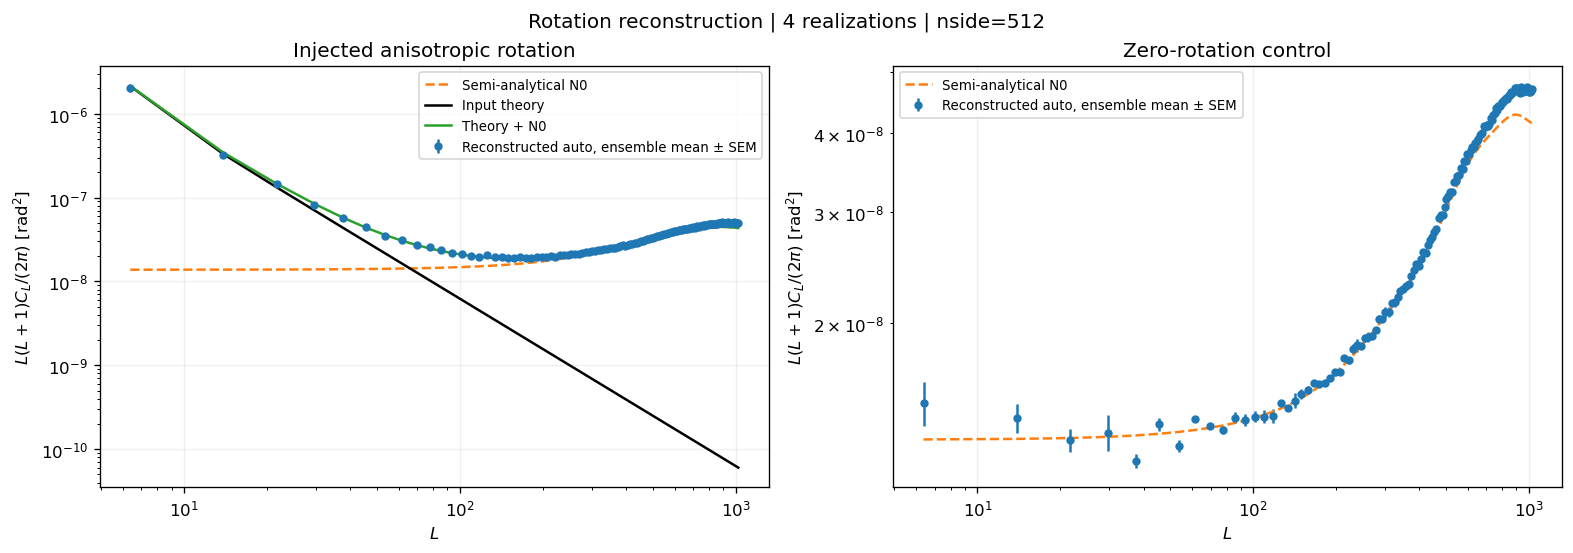

In [9]:
edges = np.append(np.arange(2, lmax_qlm + 1, bin_width), lmax_qlm + 1)
bins = [np.arange(lo, hi) for lo, hi in zip(edges[:-1], edges[1:])]
weights = [(2 * L[b] + 1) / np.sum(2 * L[b] + 1) for b in bins]
L_b = np.array([np.sum(L[b] * w) for b, w in zip(bins, weights)])

def bin_D(cls):
    return np.stack([np.sum(cls[..., b] * w, axis=-1)
                     for b, w in zip(bins, weights)], axis=-1)

def mean_sem(samples):
    return samples.mean(axis=0), samples.std(axis=0, ddof=1) / np.sqrt(len(samples))

bandpowers = {key: bin_D(value) for key, value in spectra.items()}
theory_b = bin_D(cl_theory)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
for ax, prefix, title in [(axes[0], '', 'Injected anisotropic rotation'),
                          (axes[1], 'null_', 'Zero-rotation control')]:
    auto_mean, auto_sem = mean_sem(bandpowers[prefix + 'auto'])
    noise_mean = bandpowers[prefix + 'noise'].mean(axis=0)
    ax.errorbar(L_b, auto_mean, yerr=auto_sem, fmt='o', ms=4,
                label='Reconstructed auto, ensemble mean ± SEM')
    ax.loglog(L_b, noise_mean, '--', label='Semi-analytical N0')
    if not prefix:
        ax.plot(L_b, theory_b, color='black', label='Input theory')
        ax.plot(L_b, theory_b + noise_mean, label='Theory + N0')
    ax.set(title=title, xlabel='$L$', ylabel=r'$L(L+1)C_L/(2\pi)$ [rad$^2$]', yscale='log')
    ax.legend(fontsize=8)
fig.suptitle(f'Rotation reconstruction | {nsims} realizations | nside={nside}')
plt.show()

## Cross-spectrum response and noise-subtracted diagnostics
Points are $(2L+1)$-weighted bandpowers; all theory comparisons use identical bins. Error bars are the standard error of the ensemble mean, measured across independent realization indices. The signal and null cases are paired, so they are not independent of one another. With a small ensemble these uncertainty estimates are noisy.

The cross-minus-input diagnostic uses each realization's own input auto-spectrum, reducing input sample variance. A response ratio near one and null residuals near zero are the desired outcomes. These are diagnostic plots rather than hard acceptance thresholds.

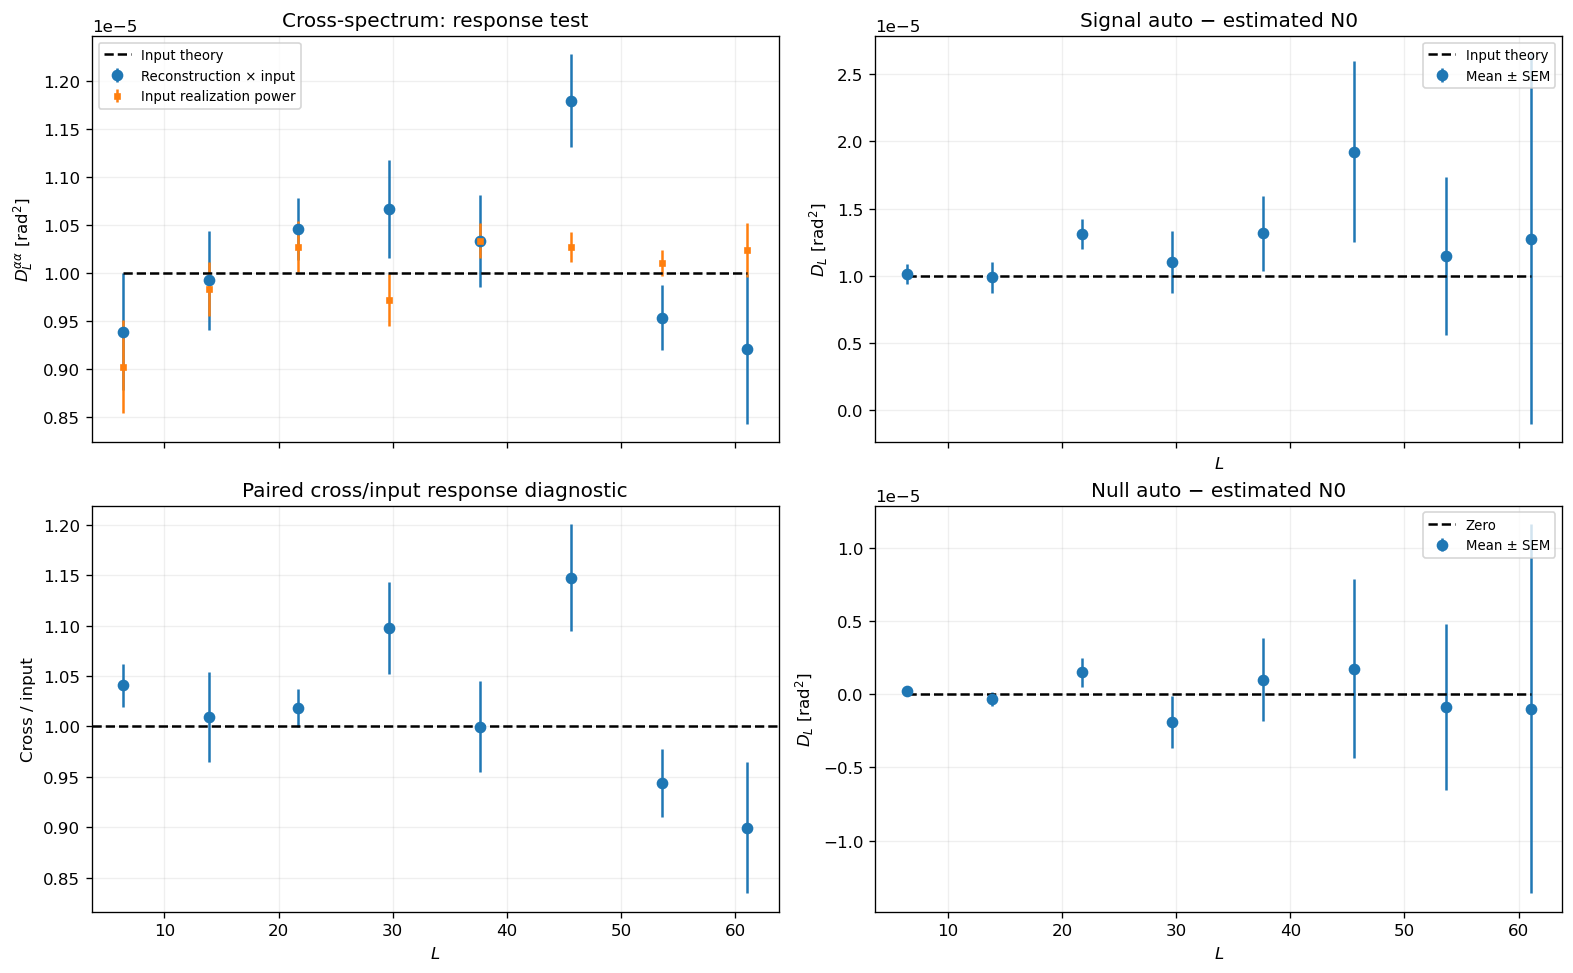

Mean fractional cross-minus-input residual: +0.019 ± 0.017 (SEM; equal bin weights)


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, layout='constrained')
cross_mean, cross_sem = mean_sem(bandpowers['cross'])
input_mean, input_sem = mean_sem(bandpowers['input'])
axes[0, 0].errorbar(L_b, cross_mean, cross_sem, fmt='o', label='Reconstruction × input')
axes[0, 0].errorbar(L_b, input_mean, input_sem, fmt='s', ms=3, label='Input realization power')
axes[0, 0].plot(L_b, theory_b, 'k--', label='Input theory')
axes[0, 0].set(title='Cross-spectrum: response test', ylabel=r'$D_L^{\alpha\alpha}$ [rad$^2$]')
axes[0, 0].legend(fontsize=8)

# Paired residual divided by ensemble input power, expressed as a response ratio.
delta_mean, delta_sem = mean_sem(bandpowers['cross'] - bandpowers['input'])
axes[1, 0].errorbar(L_b, 1 + delta_mean / input_mean,
                    delta_sem / input_mean, fmt='o')
axes[1, 0].axhline(1, color='black', ls='--')
axes[1, 0].set(title='Paired cross/input response diagnostic', ylabel='Cross / input', xlabel='$L$')

for ax, prefix, title in [(axes[0, 1], '', 'Signal auto − estimated N0'),
                          (axes[1, 1], 'null_', 'Null auto − estimated N0')]:
    mean, sem = mean_sem(bandpowers[prefix + 'auto'] - bandpowers[prefix + 'noise'])
    ax.errorbar(L_b, mean, sem, fmt='o', label='Mean ± SEM')
    ax.plot(L_b, theory_b if not prefix else np.zeros_like(theory_b), 'k--',
            label='Input theory' if not prefix else 'Zero')
    ax.set(title=title, ylabel=r'$D_L$ [rad$^2$]', xlabel='$L$')
    ax.legend(fontsize=8)
plt.show()

# A compact scalar diagnostic, with paired sample uncertainty.
relative = (bandpowers['cross'] - bandpowers['input']) / theory_b
per_sim = relative.mean(axis=1)
print(f'Mean fractional cross-minus-input residual: {per_sim.mean():+.3f} '
      f'± {per_sim.std(ddof=1)/np.sqrt(nsims):.3f} (SEM; equal bin weights)')

## Visual comparison of the same realization
For visualization only, both truth and reconstruction receive the **same** fiducial Wiener filter $W_L=C_L^{\alpha\alpha}/(C_L^{\alpha\alpha}+\overline N_L)$, with $L=0,1$ removed. The spectra above use un-Wiener-filtered reconstruction alms. Maps are shown in degrees on a common color scale; the residual still contains reconstruction noise.

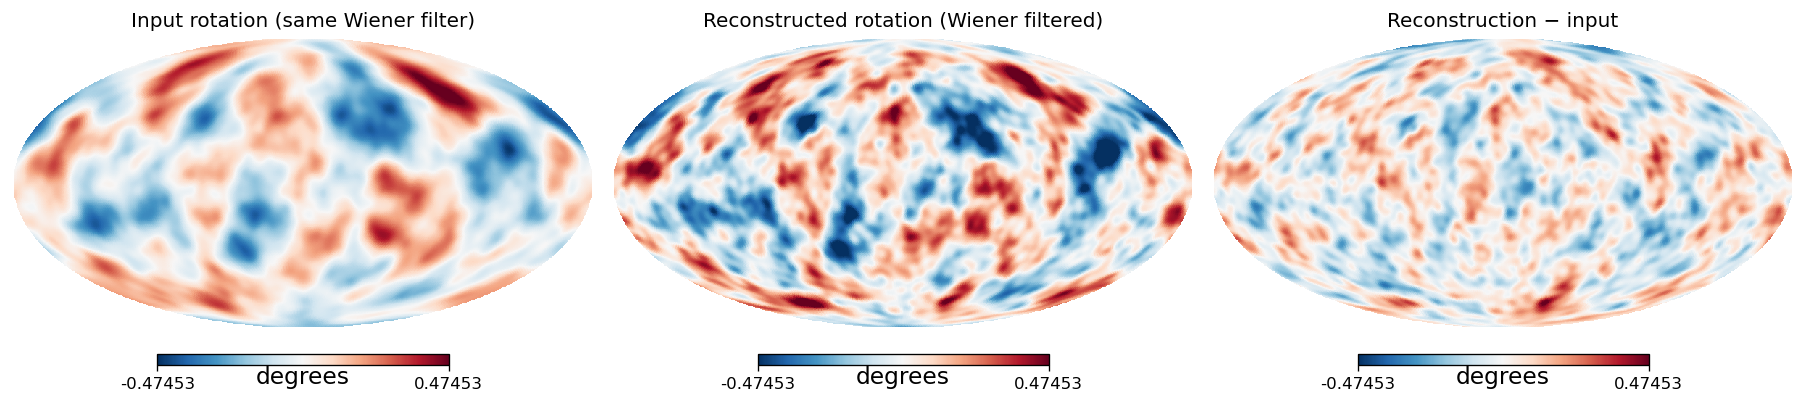

Visualization uses realization 0, reconstructed through L=64.


In [5]:
noise_mean = spectra['noise'].mean(axis=0)
wiener = np.divide(cl_theory, cl_theory + noise_mean,
                   out=np.zeros_like(cl_theory), where=(cl_theory + noise_mean) > 0)
wiener[:2] = 0
truth_map = np.rad2deg(hp.alm2map(hp.almxfl(example_truth, wiener), nside))
recon_map = np.rad2deg(hp.alm2map(hp.almxfl(example_estimate, wiener), nside))
limit = np.percentile(np.abs(np.concatenate([truth_map, recon_map])), 99)
fig = plt.figure(figsize=(15, 4.2))
for position, sky, title in [(1, truth_map, 'Input rotation (same Wiener filter)'),
                              (2, recon_map, 'Reconstructed rotation (Wiener filtered)'),
                              (3, recon_map - truth_map, 'Reconstruction − input')]:
    hp.mollview(sky, fig=fig.number, sub=(1, 3, position), title=title,
                unit='degrees', min=-limit, max=limit, cmap='RdBu_r', hold=False)
plt.show()
print(f'Visualization uses realization {first_idx}, reconstructed through L={lmax_qlm}.')